# Machine Learning Homework 2026


## Section 3 - Feature Selection: 90-Day Repeat Purchase Prediction


## 3.1. Introduction

The objective of this notebook is to identify and select relevant features for predicting whether a customer will make another purchase within the next 90 days.

Feature selection aims to reduce irrelevant and redundant information while preserving the predictive performance of the model.

We will explore and compare different feature selection approaches covered in class:

- **Filter methods:** VarianceThreshold, SelectKBest and correlation-based filtering.
- **Wrapper methods:** Recursive Feature Elimination (RFE).
- **Embedded methods:** SelectFromModel.

The selected feature subsets will be evaluated and compared to determine an appropriate set of predictors for the classification task.


### 3.2. Initial Feature Screening

Before applying feature selection methods, we identify the target variable and exclude columns that should not be used directly as predictors.

In particular, identifiers must be treated carefully, as they may introduce misleading patterns rather than meaningful predictive information.

This step builds on the exploratory analysis performed in Section 1.


In [4]:
import pandas as pd

# Load the training and test datasets
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

In [5]:

# Separate the target variable from the predictors

y = train["repeat_purchase_90d"]

X = train.drop(columns=["repeat_purchase_90d"])

print("Number of candidate features:", X.shape[1])
print("Target shape:", y.shape)


Number of candidate features: 38
Target shape: (6534,)


In [6]:

# Check the DataFrame index and available columns

print("Index name:", train.index.name)
print("Is customer_id a column?", "customer_id" in X.columns)

X.columns.tolist()


Index name: None
Is customer_id a column? True


['Total a Pagar',
 'Total Bruto',
 'Total Liquido',
 'Total Imp_',
 'Total Portes',
 'Total Desc_ Global',
 'Total Desc_ Linha',
 'Custo',
 'N_ Detalhes',
 'invoice_count_current_purchase',
 'days_since_previous_purchase',
 'customer_tenure_days',
 'prior_purchase_count',
 'prior_total_spend',
 'prior_mean_purchase_value',
 'prior_std_purchase_value',
 'prior_min_purchase_value',
 'prior_max_purchase_value',
 'prior_mean_gap_days',
 'prior_std_gap_days',
 'purchase_count_30d',
 'spend_30d',
 'purchase_count_90d',
 'spend_90d',
 'purchase_count_180d',
 'spend_180d',
 'purchase_count_365d',
 'spend_365d',
 'customer_id',
 'payment_type',
 'salesperson',
 'commercial_zone',
 'transport_method',
 'warehouse',
 'document_series',
 'purchase_date',
 'ID',
 'random_noise']

In [7]:

# Inspect identifiers and date columns

print("Index name:", train.index.name)

for col in ["ID", "customer_id", "purchase_date", "random_noise"]:
    print(f"{col}: {'Present' if col in X.columns else 'Not present'}")


Index name: None
ID: Present
customer_id: Present
purchase_date: Present
random_noise: Present


In [8]:

# Remove identifiers from the candidate features

X_candidates = X.drop(columns=["customer_id", "ID"], errors="ignore")

print("Original number of features:", X.shape[1])
print("Number of candidate features:", X_candidates.shape[1])


Original number of features: 38
Number of candidate features: 36


In [9]:

# Temporarily exclude the raw purchase date
# Date-based features will be handled during preprocessing

X_candidates = X_candidates.drop(
    columns=["purchase_date"],
    errors="ignore"
)

print("Number of candidate features:", X_candidates.shape[1])


Number of candidate features: 35


The `ID` and `customer_id` columns were excluded from the candidate predictors because they are identifiers.

The raw `purchase_date` column was temporarily excluded, since date-based feature engineering will be addressed during preprocessing.

These exclusions do not modify the original dataset.

In [10]:

# Reuse the feature groups identified during EDA

numerical_features = [col for col in numeric if col in X_candidates.columns]
categorical_features = [col for col in categorical if col in X_candidates.columns]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))


NameError: name 'numeric' is not defined

In [11]:
VarianceThreshold(threshold=0)

NameError: name 'VarianceThreshold' is not defined

In [12]:

from sklearn.model_selection import train_test_split

# Select numerical features
X_numeric = X_candidates[numerical_features].copy()

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_numeric,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and fit the variance selector
selector = VarianceThreshold(threshold=0)
selector.fit(X_train)

# Identify selected and removed features
selected_features = X_train.columns[selector.get_support()].tolist()
removed_features = X_train.columns[~selector.get_support()].tolist()

print("Original features:", X_train.shape[1])
print("Selected features:", len(selected_features))
print("Removed features:", removed_features)


NameError: name 'numerical_features' is not defined

### Filter Method: VarianceThreshold

VarianceThreshold is a filter-based feature selection method that removes features with variance below a specified threshold. It is useful for identifying constant or low-variance features that may provide limited information to the model.

For this initial analysis, we selected the **29 numerical features** identified during the exploratory data analysis. The data was then split into **80% training and 20% validation**, using `stratify=y` to preserve the target class distribution in both sets.

We applied `VarianceThreshold(threshold=0)`, meaning that only features with zero variance would be removed. The selector was fitted exclusively on the training data to avoid using validation information during feature selection.

**Results:**
- Original numerical features: 29
- Selected features: 29
- Removed features: 0

All 29 numerical features were retained, indicating that none had zero variance in the training dataset.

However, VarianceThreshold does not consider the relationship between the features and the target variable (`repeat_purchase_90d`). Therefore, a feature may have high variance without being useful for predicting repeat purchases.

Since no features were removed, additional feature selection methods will be explored to identify the most relevant predictors.


In [ ]:

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer

# Handle missing values using the training median
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)

# Select the 10 highest-scoring numerical features
kbest = SelectKBest(score_func=f_classif, k=10)
kbest.fit(X_train_imputed, y_train)

# Identify selected features
kbest_features = X_train.columns[kbest.get_support()].tolist()

# Display scores for all numerical features
kbest_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": kbest.scores_
}).sort_values("Score", ascending=False)

print("Top 10 selected features:")
print(kbest_features)

display(kbest_scores)


Top 10 selected features:
['days_since_previous_purchase', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_gap_days', 'purchase_count_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d']


,Feature,Score
26,purchase_count_365d,688.649129
24,purchase_count_180d,649.250764
22,purchase_count_90d,621.051452
12,prior_purchase_count,532.734510
25,spend_180d,527.078657
23,spend_90d,431.073034
13,prior_total_spend,402.361846
20,purchase_count_30d,394.634172
18,prior_mean_gap_days,227.818158
10,days_since_previous_purchase,168.076727


### Filter Method: SelectKBest

SelectKBest is a filter-based feature selection method that ranks features according to their statistical relationship with the target variable.

For this classification task, we use the ANOVA F-test (`f_classif`) to evaluate the relationship between each numerical feature and `repeat_purchase_90d`.
We selected the ANOVA F-test (`f_classif`) because our predictors are numerical and our target is binary, allowing us to evaluate how well each feature distinguishes between customers who make a repeat purchase within 90 days and those who do not.

Unlike VarianceThreshold, SelectKBest considers the target variable when ranking features. We initially explore the 10 highest-scoring numerical features.

Since some numerical features contain missing values, temporary median imputation is applied using only the training data. The final preprocessing strategy will be integrated later. 

# IMPORTANTE (pq falta o faustino tratar os NA, na susbtituido por mediana )



The results suggest that previous purchasing behaviour is strongly associated with the target variable. The selected features mainly describe purchase recency, purchase frequency, previous spending and the time between purchases.

However, some selected features may contain overlapping information, particularly purchase counts measured over different time periods.

Since SelectKBest evaluates each feature independently, further analysis is needed to identify redundant features and assess whether all selected variables contribute useful information to the predictive model.

These results are preliminary and will be reassessed using the final preprocessing and validation strategy.

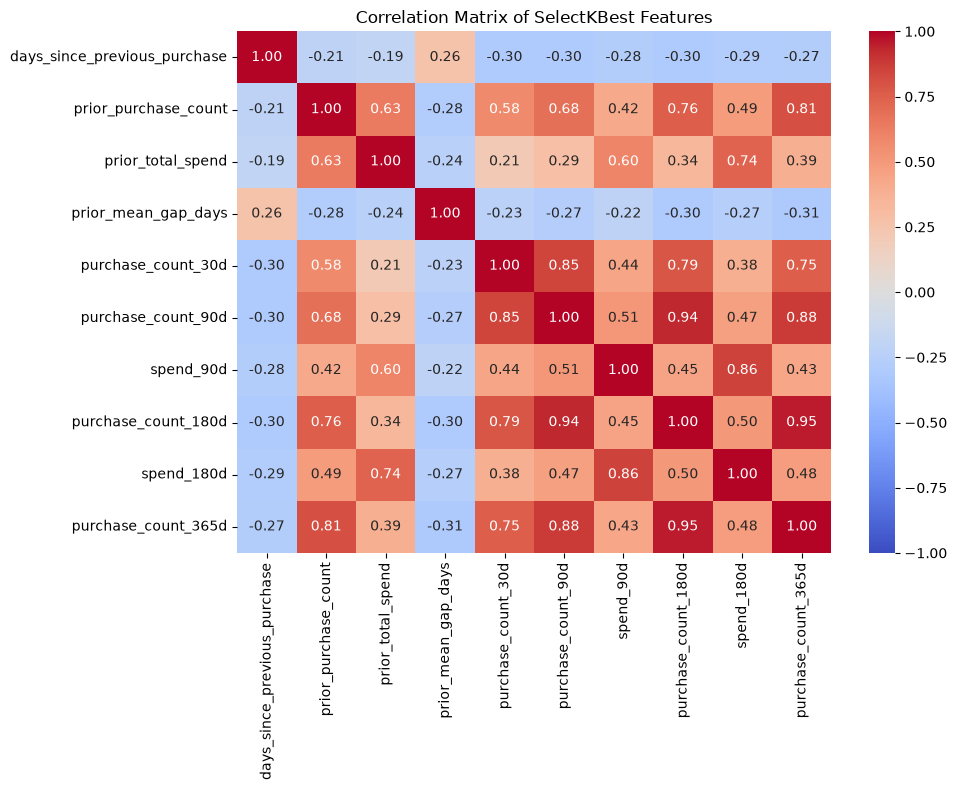

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix of the selected features
correlation_matrix = X_train[kbest_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of SelectKBest Features")
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np

# Calculate absolute correlations
corr_matrix = X_train[kbest_features].corr().abs()

# Keep only the upper triangle of the correlation matrix
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify highly correlated features
threshold = 0.90

features_to_remove = [
    col for col in upper_triangle.columns
    if any(upper_triangle[col] > threshold)
]

# Keep the remaining features
features_after_correlation = [
    col for col in kbest_features
    if col not in features_to_remove
]

print("Features to remove:", features_to_remove)
print("Remaining features:", features_after_correlation)
print("Number of remaining features:", len(features_after_correlation))


Features to remove: ['purchase_count_180d', 'purchase_count_365d']
Remaining features: ['days_since_previous_purchase', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_gap_days', 'purchase_count_30d', 'purchase_count_90d', 'spend_90d', 'spend_180d']
Number of remaining features: 8


### Correlation-Based Feature Selection

Correlation-based filtering is used to identify redundant features that may contain overlapping information.

After applying SelectKBest, we calculated the Pearson correlation matrix for the 10 selected numerical features using the training dataset.

The correlation matrix revealed several strong positive relationships, particularly between purchase frequency variables measured over different time periods.

The strongest correlations were:

- `purchase_count_180d` and `purchase_count_365d`: **0.95**
- `purchase_count_90d` and `purchase_count_180d`: **0.94**
- `purchase_count_90d` and `purchase_count_365d`: **0.88**
- `spend_90d` and `spend_180d`: **0.86**

These relationships are expected because the purchase history variables represent overlapping time periods.

To identify potentially redundant predictors, we applied an absolute correlation threshold of **0.90**. Features exceeding this threshold were flagged for possible removal.

This method helps identify highly correlated predictors, but correlation alone does not determine which feature is more useful for predicting the target. Therefore, any proposed exclusions should be reviewed using feature relevance and model performance before finalising the selected feature set.

Overall, the analysis suggests that some purchase frequency variables contain overlapping information, while other selected features provide more distinct information about customer purchasing behaviour.

In [ ]:

# Compare ANOVA scores of highly correlated features
features_to_compare = [
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d"
]

display(
    kbest_scores[
        kbest_scores["Feature"].isin(features_to_compare)
    ].sort_values("Score", ascending=False)
)


,Feature,Score
26,purchase_count_365d,688.649129
24,purchase_count_180d,649.250764
22,purchase_count_90d,621.051452


### ANOVA Score Comparison

After identifying highly correlated features, we compared their ANOVA F-scores to better understand their individual relationships with the target variable (`repeat_purchase_90d`).

The ANOVA F-test evaluates whether the mean value of a numerical feature differs between customers who make a repeat purchase and those who do not, relative to the variation within each group.

The results were:

- `purchase_count_365d`: **688.65**
- `purchase_count_180d`: **649.25**
- `purchase_count_90d`: **621.05**

The 365-day purchase count obtained the highest ANOVA F-score, indicating the strongest statistical separation between the two target groups among these three features.

However, a higher ANOVA score does not necessarily mean better predictive performance. Therefore, these scores were considered alongside the correlation analysis rather than being used as the only criterion for feature removal.

In [ ]:

# Remove the 180-day purchase count due to high correlation
features_to_remove = ["purchase_count_180d"]

features_after_correlation = [
    feature for feature in kbest_features
    if feature not in features_to_remove
]

print("Features removed:", features_to_remove)
print("Remaining features:", features_after_correlation)
print("Number of remaining features:", len(features_after_correlation))


Features removed: ['purchase_count_180d']
Remaining features: ['days_since_previous_purchase', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_gap_days', 'purchase_count_30d', 'purchase_count_90d', 'spend_90d', 'spend_180d', 'purchase_count_365d']
Number of remaining features: 9


### Correlation Filtering Results and Interpretation

Based on the correlation analysis and ANOVA F-scores, we decided to provisionally remove `purchase_count_180d`.

This feature showed a strong correlation with both `purchase_count_90d` (0.94) and `purchase_count_365d` (0.95), suggesting that it contains information overlapping with the other two variables.

In contrast, the correlation between `purchase_count_90d` and `purchase_count_365d` was 0.88, below our selected threshold of 0.90.

Therefore, we retained both the 90-day and 365-day purchase counts to preserve information about recent and longer-term purchasing behaviour, while reducing redundancy.

This reduced the selected numerical features from **10 to 9**.

**This decision is preliminary.** During model training and validation, we will compare the model's performance with and without `purchase_count_180d` to assess whether removing it improves, maintains or reduces predictive performance.

The final feature subset will be determined based on these results rather than correlation and ANOVA scores alone.

In [ ]:

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Handle missing values using the training data
rfe_imputer = SimpleImputer(strategy="median")
X_train_rfe = rfe_imputer.fit_transform(X_train)

# Standardise numerical features
rfe_scaler = StandardScaler()
X_train_rfe_scaled = rfe_scaler.fit_transform(X_train_rfe)

# Define the classification model
rfe_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Apply Recursive Feature Elimination
rfe = RFE(
    estimator=rfe_model,
    n_features_to_select=10,
    step=1
)

rfe.fit(X_train_rfe_scaled, y_train)

# Identify selected features
rfe_features = X_train.columns[rfe.support_].tolist()

print("RFE selected features:")
print(rfe_features)
print("Number of selected features:", len(rfe_features))


RFE selected features:
['Total Liquido', 'Total Imp_', 'Total Desc_ Linha', 'Custo', 'customer_tenure_days', 'prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d']
Number of selected features: 10


###  Wrapper Method: Recursive Feature Elimination (RFE)

Recursive Feature Elimination (RFE) is a wrapper-based feature selection method that uses a machine learning model to identify relevant predictors.

Unlike filter methods, which evaluate features using statistical measures, RFE repeatedly fits a model, ranks features according to their importance and removes the least important features until the desired number remains.

For this analysis, we use **Logistic Regression** as the estimator because our target variable (`repeat_purchase_90d`) represents a binary classification problem.

Before applying RFE, missing numerical values are imputed using the median and features are standardised to ensure that differences in scale do not distort the Logistic Regression coefficients.

We initially select 10 features from the 29 numerical predictors. This allows us to compare the RFE results with the 10 features previously selected by SelectKBest.

The analysis is performed using training data only, and the selected features will be evaluated later using the final validation strategy.

### ATENÇÃO, NA SUBSTRITUIDO POR mediana 


### RFE Results and Interpretation

Recursive Feature Elimination (RFE), using Logistic Regression as the estimator, selected 10 numerical features from the original set of 29.

When comparing these results with SelectKBest, we found that five features were selected by both methods: `prior_purchase_count`, `purchase_count_30d`, `purchase_count_90d`, `purchase_count_180d`, and `purchase_count_365d`.

The remaining five features selected by RFE were `Total Liquido`, `Total Imp_`, `Total Desc_ Linha`, `Custo`, and `customer_tenure_days`.

These differences arise because SelectKBest evaluates the statistical relationship between each feature and the target individually, whereas RFE evaluates features through a Logistic Regression model, considering them together during the selection process.

Interestingly, RFE selected `purchase_count_180d`, which had been provisionally removed during correlation filtering. This highlights that different feature selection methods may produce different subsets.

Therefore, neither subset will be considered definitive at this stage. Their predictive performance will be compared during model validation to determine which combination of features is most useful.

In [ ]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer

# Temporarily impute missing values using training data only
embedded_imputer = SimpleImputer(strategy="median")
X_train_embedded = embedded_imputer.fit_transform(X_train)

# Define the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Select the 10 most important numerical features
embedded_selector = SelectFromModel(
    estimator=rf_model,
    threshold=-float("inf"),
    max_features=10
)

embedded_selector.fit(X_train_embedded, y_train)

# Get selected feature names
embedded_features = X_train.columns[
    embedded_selector.get_support()
].tolist()

print("Embedded selected features:")
print(embedded_features)
print("Number of selected features:", len(embedded_features))


Embedded selected features:
['Total Bruto', 'Total Imp_', 'Custo', 'prior_total_spend', 'prior_mean_gap_days', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'random_noise']
Number of selected features: 10


### Embedded Method: SelectFromModel

Embedded methods perform feature selection using information obtained during model training.

For this analysis, we use `SelectFromModel` with a Random Forest classifier. Random Forest estimates feature importance based on how much each feature contributes to reducing impurity across its decision trees.

Unlike RFE, which repeatedly removes features, SelectFromModel uses the feature importance scores from a fitted model to select a subset of predictors.

We apply this method to the original 29 numerical features to compare its results with SelectKBest and RFE.

Missing values are temporarily replaced using median imputation fitted on the training data. No scaling is required for Random Forest.

The selected features will be evaluated later to determine whether they improve predictive performance.
# NA subtituido pela mediana